# Example of the aitlas toolbox in the context of semantic segmentation

The PASTIS-HD dataset is multi-temporal. This notebook shows how to visualize the images and corresponding masks, obtain statistis and plot a time series graph. The SPOT imagery is not multi-temporal and is used for standard semantic segmentation.

## Import the required packages

In [ ]:
from aitlas.datasets import PASTISHDDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import matplotlib.pyplot as plt

## Visualize images and masks

In [ ]:
# specific bands
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/pastis_hd",
    "imagery": "all",
    "selection": "bands",
    "bands_s2": ["B02","B03","B04","B05","B06"],
    "bands_s1": ["VV","VH"]
}
dataset = PASTISHDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 2433


In [ ]:
# rgb images
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/pastis_hd",
    "imagery": "all"
}
dataset = PASTISHDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 2433


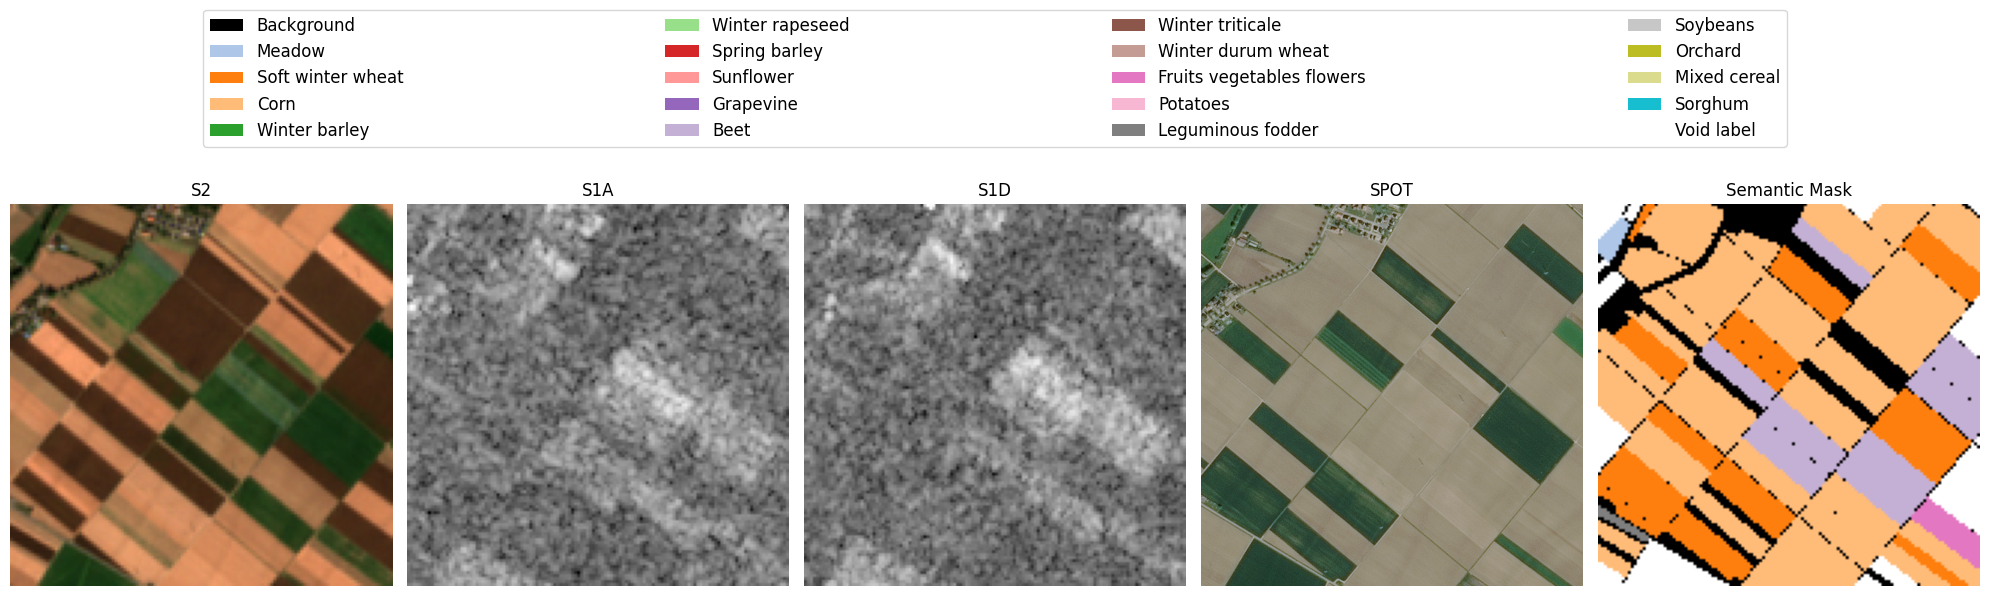

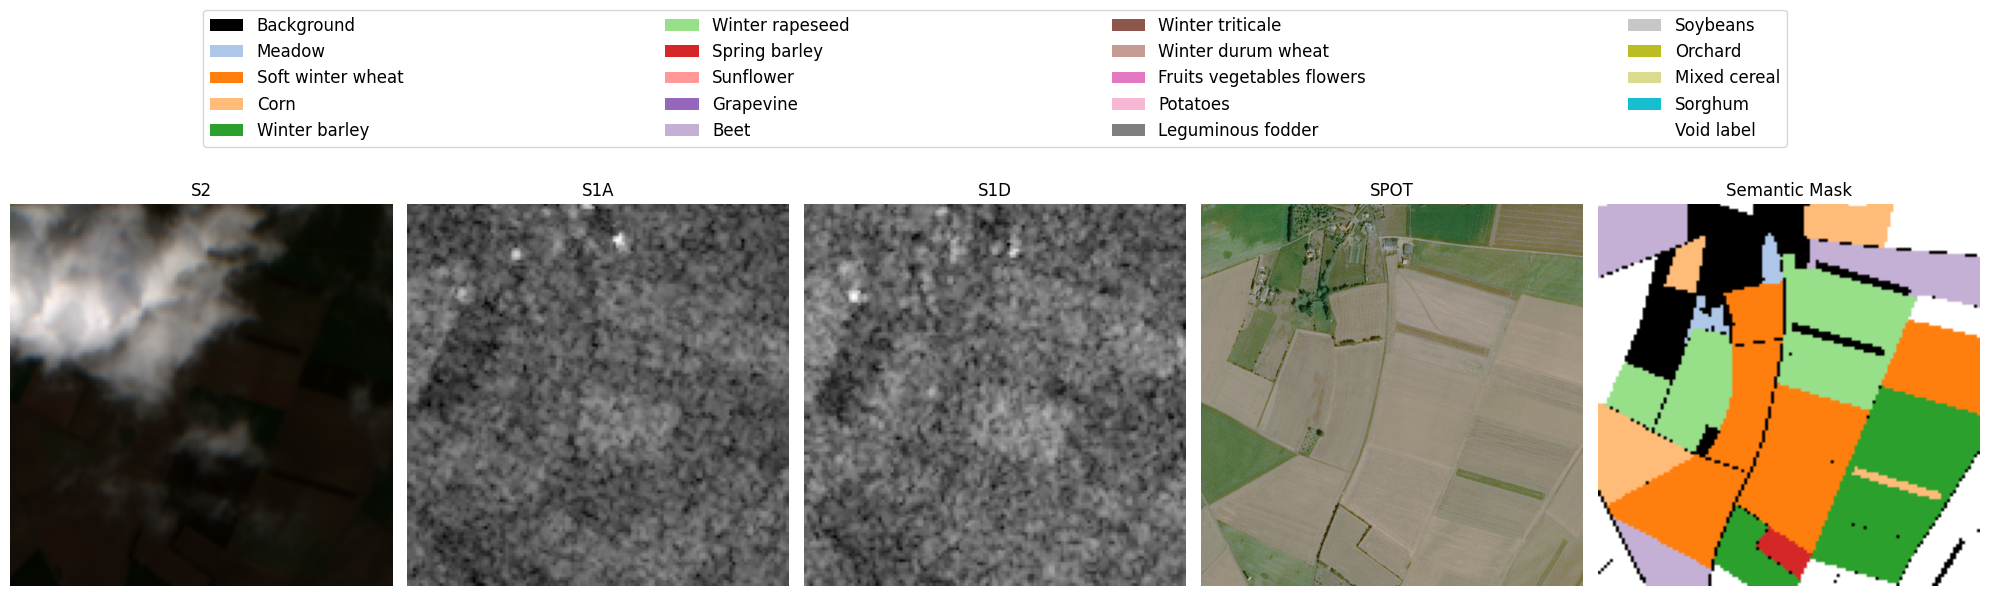

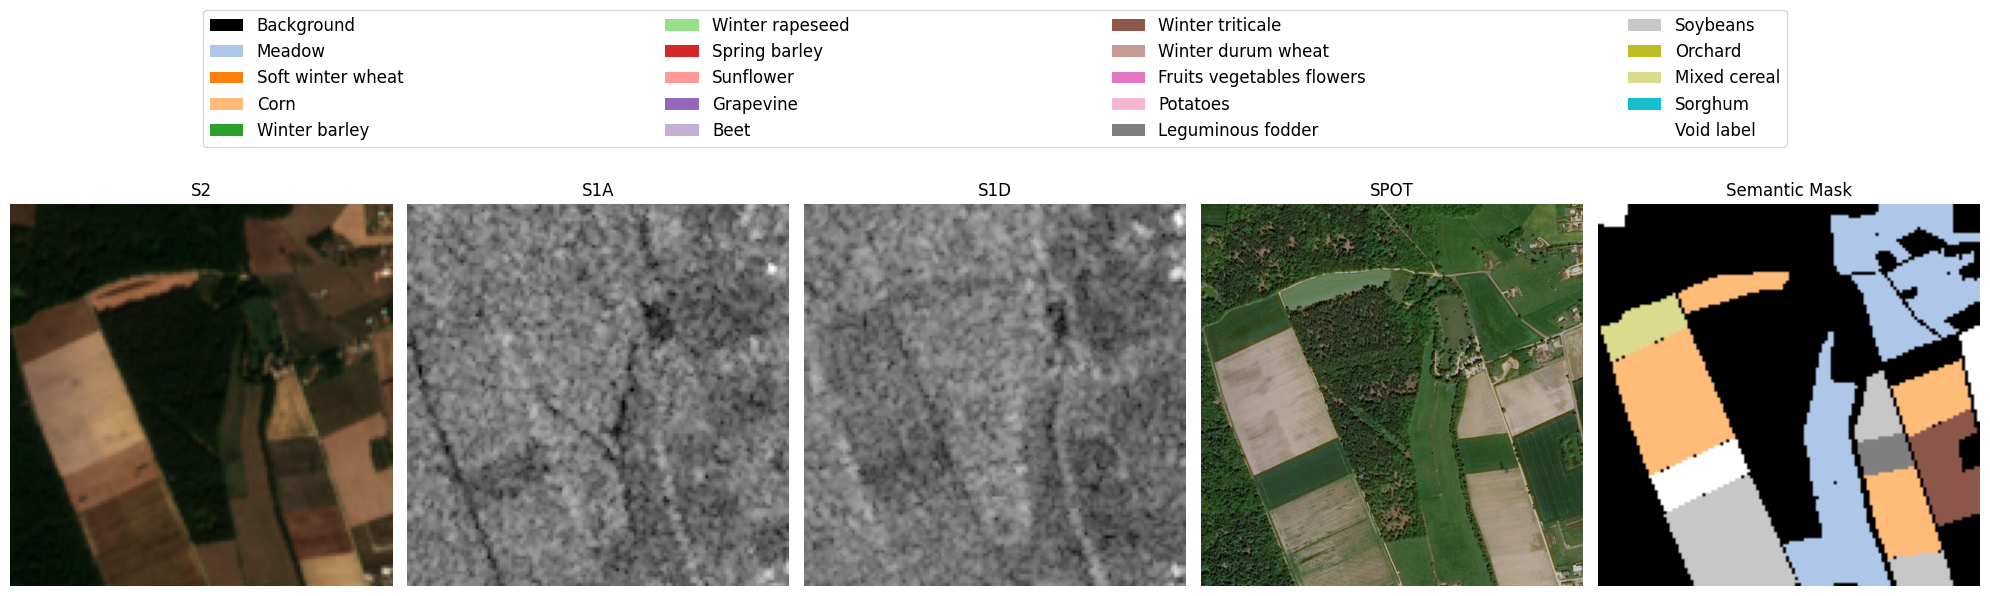

In [16]:
dataset.show_image(10) # plots the first time step and rgb images
dataset.show_image(150)
dataset.show_image(350);

In [19]:
dataset.data_distribution_table()

,Number of pixels
Background,15907494.0
Meadow,7289116.0
Soft winter wheat,2733960.0
Corn,3451442.0
Winter barley,810895.0
Winter rapeseed,705329.0
Spring barley,254693.0
Sunflower,395551.0
Grapevine,1108797.0
Beet,324825.0


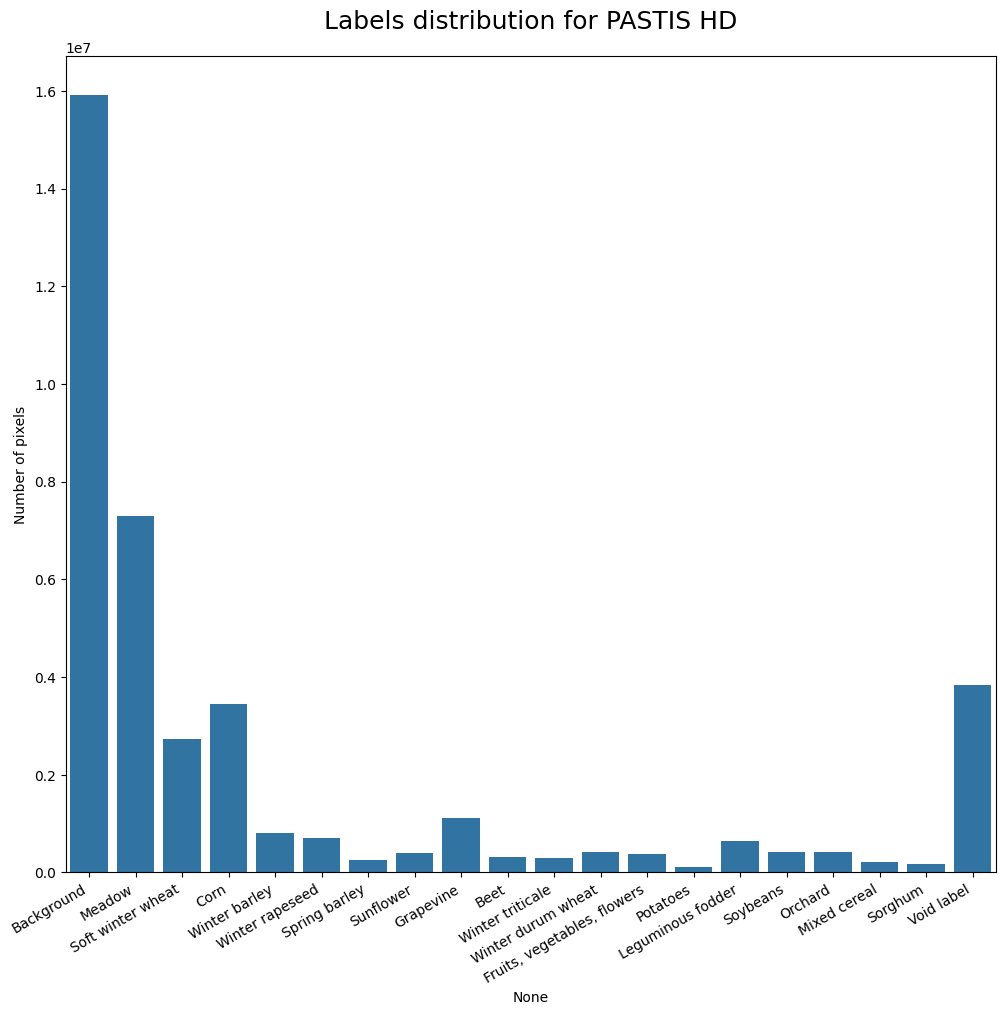

In [87]:
dataset.data_distribution_barchart();

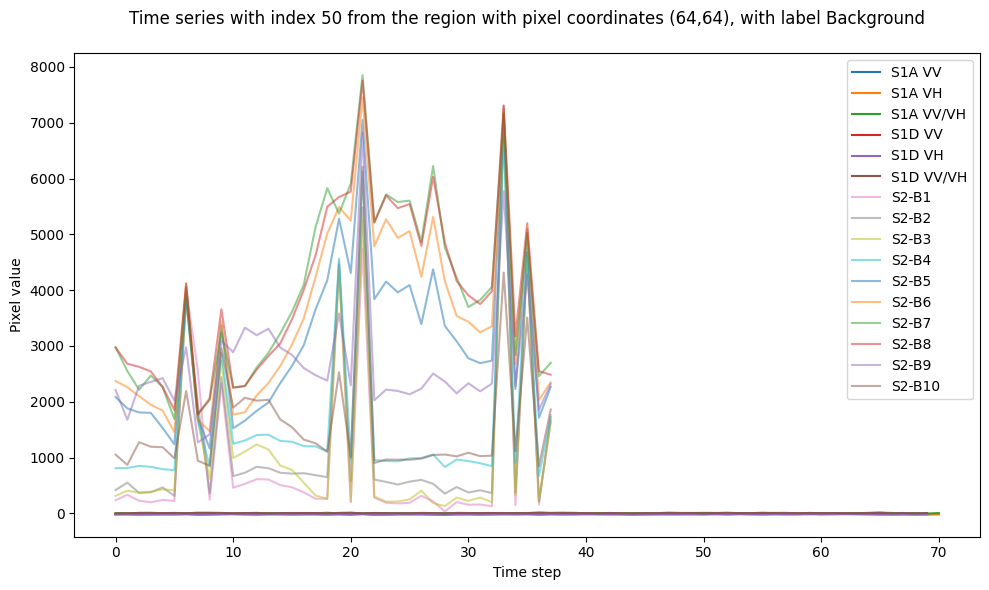

In [32]:
dataset.show_timeseries(index=50, longitude=64, latitude=64);

## Load training data (SPOT imagery)

In [7]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/pastis_hd/",
    "csv_file": "/home/dragik/data/FAIR_EO/pastis_hd/pastis_hd_train.csv",
    "selection": "rgb",
    "imagery": "SPOT",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = PASTISHDDataset(train_dataset_config)

len(train_dataset)

1459

## Create the model

In [61]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/pastis_hd"
model_config = {
    "num_classes": 20, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [62]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-11-24 08:42:52,520 INFO Starting training.
training: 100%|██████████| 46/46 [00:28<00:00,  1.59it/s]
2025-11-24 08:43:21,595 INFO epoch: 1, time: 29, loss:  0.88452
testing on train set: 100%|██████████| 46/46 [00:31<00:00,  1.47it/s]
2025-11-24 08:43:54,678 INFO IOU:0.15866769637782602, IOU mean:0.0907474614931582, IOU per Class:[5.84519367e-01 3.43893841e-01 1.52345881e-01 2.27629012e-01
 1.60345295e-02 7.12870180e-02 0.00000000e+00 2.97405397e-02
 1.51383290e-01 3.67562748e-04 1.95784995e-02 6.22645931e-02
 1.86901783e-02 5.16367520e-03 0.00000000e+00 1.87328235e-03
 0.00000000e+00 5.01793530e-03 1.05357864e-02 1.14624239e-01]
training: 100%|██████████| 46/46 [00:30<00:00,  1.49it/s]
2025-11-24 08:44:25,598 INFO epoch: 2, time: 31, loss:  0.84596
testing on train set: 100%|██████████| 46/46 [00:30<00:00,  1.49it/s]
2025-11-24 08:44:56,632 INFO IOU:0.2955728416339243, IOU mean:0.11399846329128294, IOU per Class:[5.78778903e-01 3.66274204e-01 2.09043073e-01 2.69302741e-01
 5.8095

0.37244680722009815

## Evaluate the model

In [63]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/pastis_hd/",
    "csv_file": "/home/dragik/data/FAIR_EO/pastis_hd/pastis_hd_val.csv",
    "selection": "rgb",
    "imagery": "SPOT",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = PASTISHDDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/pastis_hd/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

487


2025-11-24 08:59:40,003 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/pastis_hd/checkpoint.pth.tar
2025-11-24 08:59:40,415 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/pastis_hd/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 122/122 [00:09<00:00, 12.69it/s]


[{'IOU': 0.44067234015334844,
  'IOU mean': 0.13369711978708526,
  'IOU per Class': array([0.61926672, 0.43317291, 0.4527543 , 0.43021614, 0.        ,
         0.2841818 , 0.        , 0.        , 0.23681128, 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.21753925])}]

## Predictions

2025-11-24 09:03:46,765 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/pastis_hd/checkpoint.pth.tar
2025-11-24 09:03:47,093 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/pastis_hd/checkpoint.pth.tar at epoch 11


487


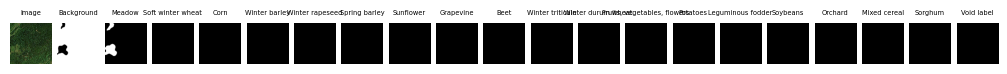

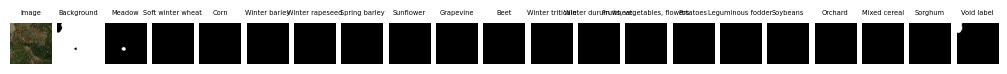

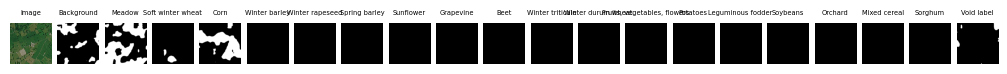

In [67]:
model_path = "/home/dragik/data/FAIR_EO/experiments/pastis_hd/checkpoint.pth.tar"
labels = ["Background",
        "Meadow",
        "Soft winter wheat",
        "Corn",
        "Winter barley",
        "Winter rapeseed",
        "Spring barley",
        "Sunflower",
        "Grapevine",
        "Beet",
        "Winter triticale",
        "Winter durum wheat",
        "Fruits, vegetables, flowers",
        "Potatoes",
        "Leguminous fodder",
        "Soybeans",
        "Orchard",
        "Mixed cereal",
        "Sorghum",
        "Void label"]
transform = ResizeToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/pastis_hd/",
    "csv_file": "/home/dragik/data/FAIR_EO/pastis_hd/pastis_hd_test.csv",
    "selection": "rgb",
    "imagery": "SPOT",
}

test_dataset = PASTISHDDataset(test_dataset_config)
print(len(test_dataset))

plt.rcParams.update({'font.size': 4})

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_masks(image, labels, transform)